# 01 — Exploratory analysis: German electricity demand

**Goal:** understand the structure of hourly load (2015 – Sep 2020) before modeling: cycles,
calendar effects, weather dependence, autocorrelation, the 2020 COVID shock, and how good the
TSOs' official day-ahead forecast is.

Figures are saved to `reports/figures/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.nonparametric.smoothers_lowess import lowess

from energy_demand_forecasting.data import PROJECT_ROOT
from energy_demand_forecasting.features import (
    LOCAL_TZ,
    TARGET,
    TSO_FORECAST,
    calendar_features,
    load_dataset,
)

FIG = PROJECT_ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")


df = load_dataset()
cal = calendar_features(df.index)
d = df.join(cal)
d["load_gw"] = d[TARGET] / 1000
d["local"] = d.index.tz_convert(LOCAL_TZ)
print(d.shape, d.index.min(), "->", d.index.max())

Matplotlib is building the font cache; this may take a moment.


(50400, 33) 2015-01-01 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00


## 1. The whole series: level, trend, seasonality

utc_timestamp
2015    54.74
2016    55.44
2017    56.18
2018    56.95
2019    55.99
2020    53.05
Name: load_gw, dtype: float64

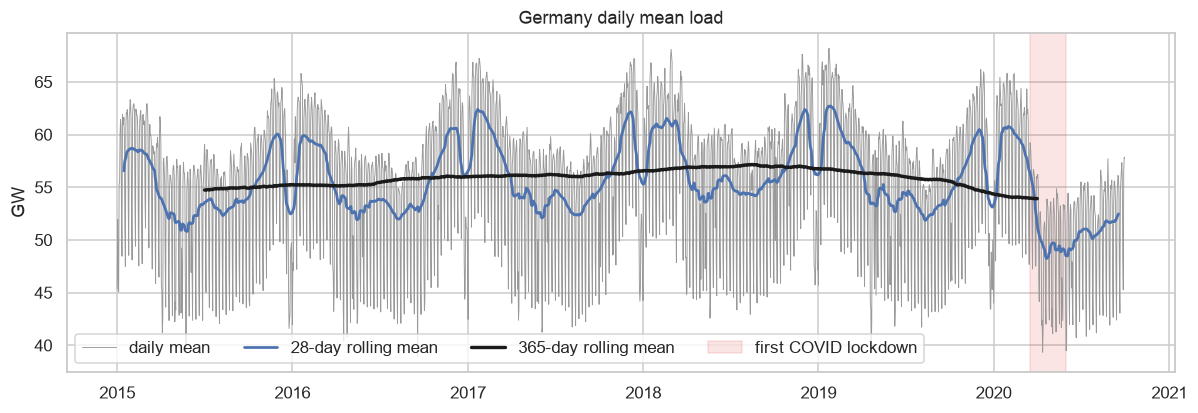

In [2]:
daily = d["load_gw"].resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily, lw=0.6, color="0.6", label="daily mean")
ax.plot(daily.rolling(28, center=True).mean(), lw=1.8, label="28-day rolling mean")
ax.plot(
    daily.rolling(365, center=True).mean(),
    lw=2.2,
    color="k",
    label="365-day rolling mean",
)
ax.axvspan(
    pd.Timestamp("2020-03-16", tz="UTC"),
    pd.Timestamp("2020-05-31", tz="UTC"),
    color="tab:red",
    alpha=0.12,
    label="first COVID lockdown",
)
ax.set(title="Germany daily mean load", ylabel="GW")
ax.legend(loc="lower left", ncols=4)
save(fig, "01_series_overview")
yearly = d.groupby(d.index.year)["load_gw"].mean().round(2)
yearly

## 2. Daily and weekly cycles (local time)

Mon    0.975
Tue    0.998
Wed    1.000
Thu    1.002
Fri    0.978
Sat    0.837
Sun    0.770
Name: level vs Tue-Thu, dtype: float64

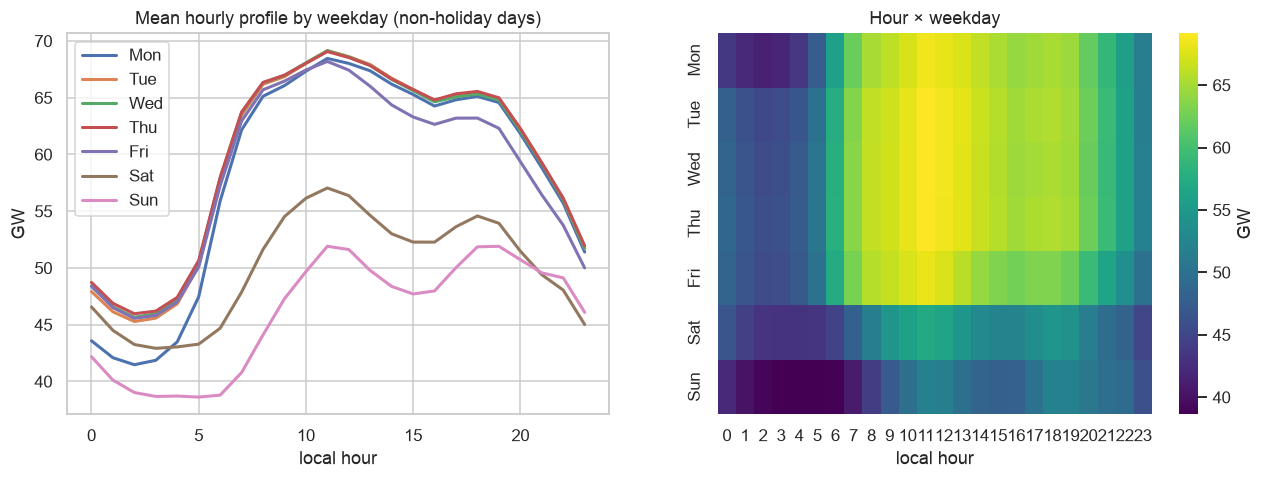

In [3]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
normal = d[(d.holiday_share == 0) & (d.is_xmas_period == 0)]
pivot = normal.pivot_table(
    index="hour", columns="dow", values="load_gw", aggfunc="mean"
)
pivot.columns = dow_names

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pivot.plot(ax=axes[0], lw=2)
axes[0].set(
    title="Mean hourly profile by weekday (non-holiday days)",
    xlabel="local hour",
    ylabel="GW",
)
sns.heatmap(pivot.T, cmap="viridis", ax=axes[1], cbar_kws={"label": "GW"})
axes[1].set(title="Hour × weekday", xlabel="local hour", ylabel="")
save(fig, "02_daily_weekly_profile")
(pivot.mean() / pivot.mean()[["Tue", "Wed", "Thu"]].mean()).round(3).rename(
    "level vs Tue-Thu"
)

## 3. Annual seasonality and how it changes the daily shape

month,1,2,3,4,5,6,7,8,9,10,11,12
mean GW,59.4,60.0,57.6,53.2,52.3,53.1,53.5,52.6,53.7,55.6,59.2,56.9


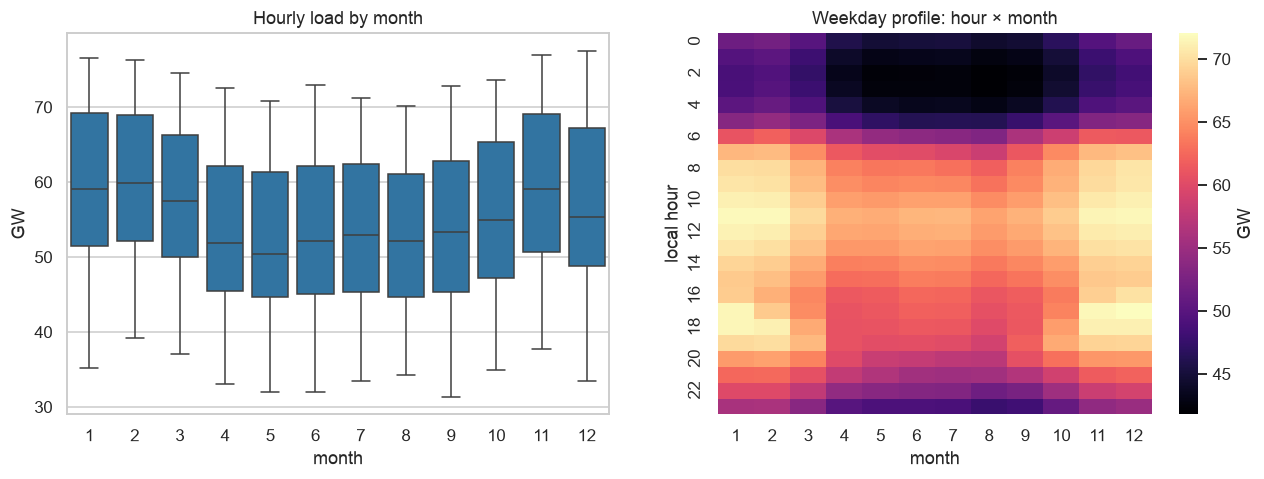

In [4]:
hm = normal[normal.dow < 5].pivot_table(index="hour", columns="month", values="load_gw")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=d, x="month", y="load_gw", ax=axes[0], color="tab:blue", fliersize=1)
axes[0].set(title="Hourly load by month", ylabel="GW")
sns.heatmap(hm, cmap="magma", ax=axes[1], cbar_kws={"label": "GW"})
axes[1].set(title="Weekday profile: hour × month", xlabel="month", ylabel="local hour")
save(fig, "03_annual_seasonality")
d.groupby("month")["load_gw"].mean().round(1).to_frame("mean GW").T

## 4. Weather: is the temperature effect nonlinear?

Daily means, working days only, to separate weather from the calendar.

working-day load: <5°C 63.6 GW | 12-20°C 57.5 GW | >22°C 57.9 GW
Pearson r (daily, working days): -0.755 | Spearman: -0.762


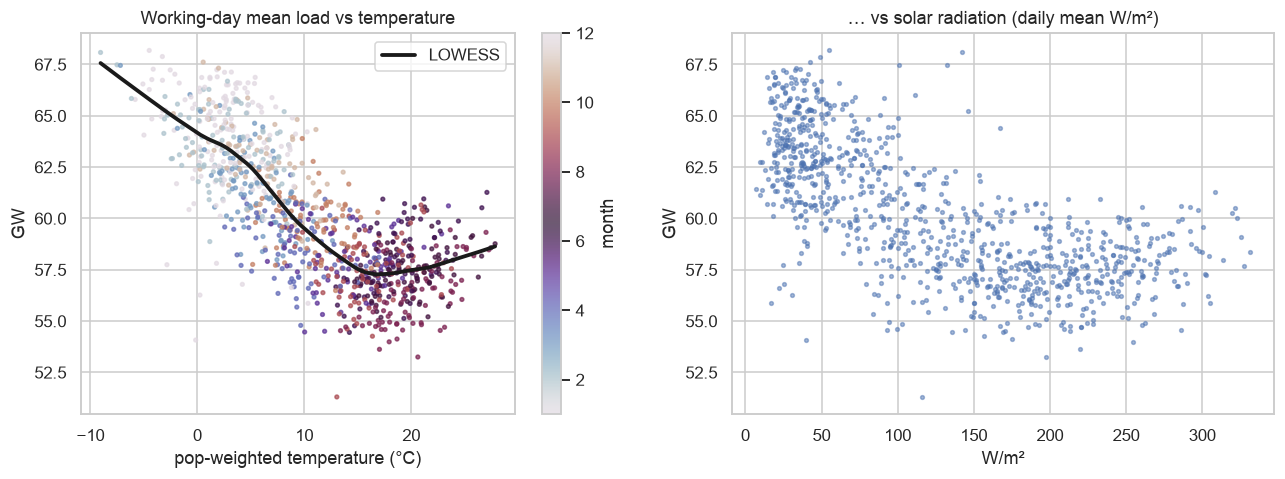

In [5]:
dd = d.resample("D").agg(
    {
        "load_gw": "mean",
        "w_temperature_2m": "mean",
        "w_shortwave_radiation": "mean",
        "is_weekend": "max",
        "holiday_share": "max",
        "is_xmas_period": "max",
    }
)
dd = dd[dd.index < "2020-03-01"]  # exclude COVID
work = dd[(dd.is_weekend == 0) & (dd.holiday_share == 0) & (dd.is_xmas_period == 0)]
fit = lowess(work.load_gw, work.w_temperature_2m, frac=0.3)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sc = axes[0].scatter(
    work.w_temperature_2m,
    work.load_gw,
    s=6,
    c=work.index.month,
    cmap="twilight",
    alpha=0.7,
)
axes[0].plot(fit[:, 0], fit[:, 1], color="k", lw=2.5, label="LOWESS")
axes[0].set(
    title="Working-day mean load vs temperature",
    xlabel="pop-weighted temperature (°C)",
    ylabel="GW",
)
plt.colorbar(sc, ax=axes[0], label="month")
axes[0].legend()
axes[1].scatter(work.w_shortwave_radiation, work.load_gw, s=6, alpha=0.5)
axes[1].set(title="… vs solar radiation (daily mean W/m²)", xlabel="W/m²", ylabel="GW")
save(fig, "04_weather_dependence")

cold, mild, hot = (
    work[work.w_temperature_2m < 5],
    work[work.w_temperature_2m.between(12, 20)],
    work[work.w_temperature_2m > 22],
)
print(
    f"working-day load: <5°C {cold.load_gw.mean():.1f} GW | 12-20°C {mild.load_gw.mean():.1f} GW | >22°C {hot.load_gw.mean():.1f} GW"
)
print(
    "Pearson r (daily, working days):",
    round(work.load_gw.corr(work.w_temperature_2m), 3),
    "| Spearman:",
    round(work.load_gw.corr(work.w_temperature_2m, method="spearman"), 3),
)

## 5. Holidays and the Christmas period

,load vs normal (%),count
holiday_share,,
none,-0.2,1231
<20%,-1.2,23
20-50%,-5.7,10
50-80%,-9.3,17
national,-19.0,66


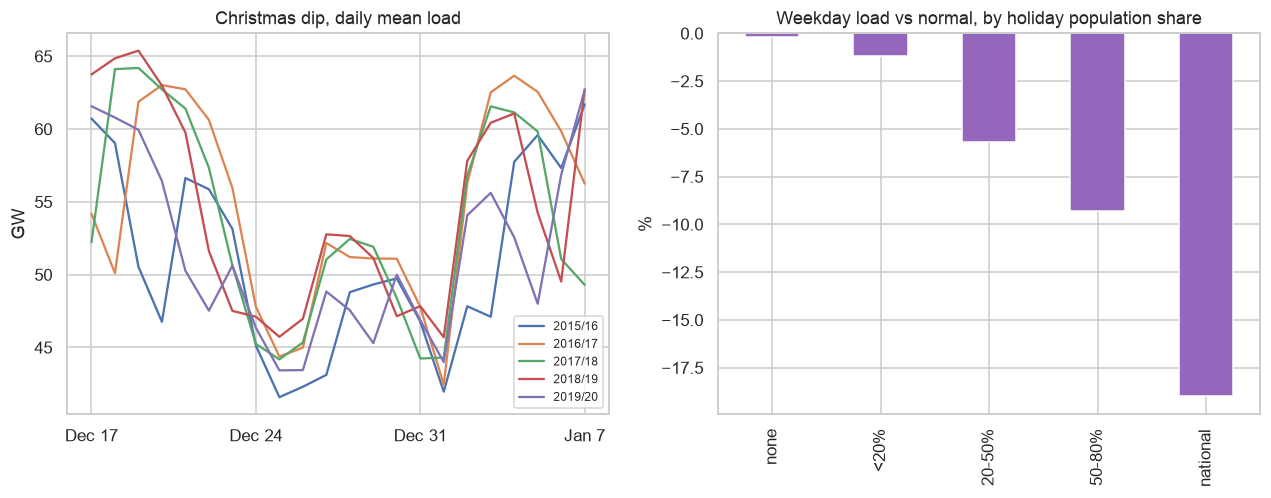

In [6]:
dd2 = d.resample("D").agg(
    {"load_gw": "mean", "holiday_share": "max", "dow": "first", "is_xmas_period": "max"}
)
dd2 = dd2[dd2.index < "2020-03-01"]
# Holiday effect relative to the same weekday's average in the surrounding 4 weeks
ref = dd2.groupby("dow")["load_gw"].transform(
    lambda s: s.rolling(9, center=True, min_periods=4).median()
)
dd2["rel"] = dd2.load_gw / ref - 1
wk = dd2[dd2.dow < 5]
bins = pd.cut(
    wk.holiday_share,
    [-0.01, 0.0, 0.2, 0.5, 0.8, 1.0],
    labels=["none", "<20%", "20-50%", "50-80%", "national"],
)
effect = (
    wk.groupby(bins, observed=True)["rel"]
    .agg(["mean", "count"])
    .assign(mean=lambda x: (x["mean"] * 100).round(1))
    .rename(columns={"mean": "load vs normal (%)"})
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for y in range(2015, 2020):
    s = d.loc[f"{y}-12-17" : f"{y + 1}-01-07", "load_gw"].resample("D").mean()
    axes[0].plot(range(len(s)), s.values, label=f"{y}/{str(y + 1)[2:]}")
axes[0].set_xticks([0, 7, 14, 21])
axes[0].set_xticklabels(["Dec 17", "Dec 24", "Dec 31", "Jan 7"])
axes[0].set(title="Christmas dip, daily mean load", ylabel="GW")
axes[0].legend(fontsize=8)
effect["load vs normal (%)"].plot.bar(ax=axes[1], color="tab:purple")
axes[1].set(
    title="Weekday load vs normal, by holiday population share", ylabel="%", xlabel=""
)
save(fig, "05_holidays")
effect

## 6. Autocorrelation

{'lag 1h': np.float64(0.966), 'lag 24h': np.float64(0.758), 'lag 48h': np.float64(0.523), 'lag 144h': np.float64(0.716), 'lag 168h': np.float64(0.91), 'lag 336h': np.float64(0.876)}


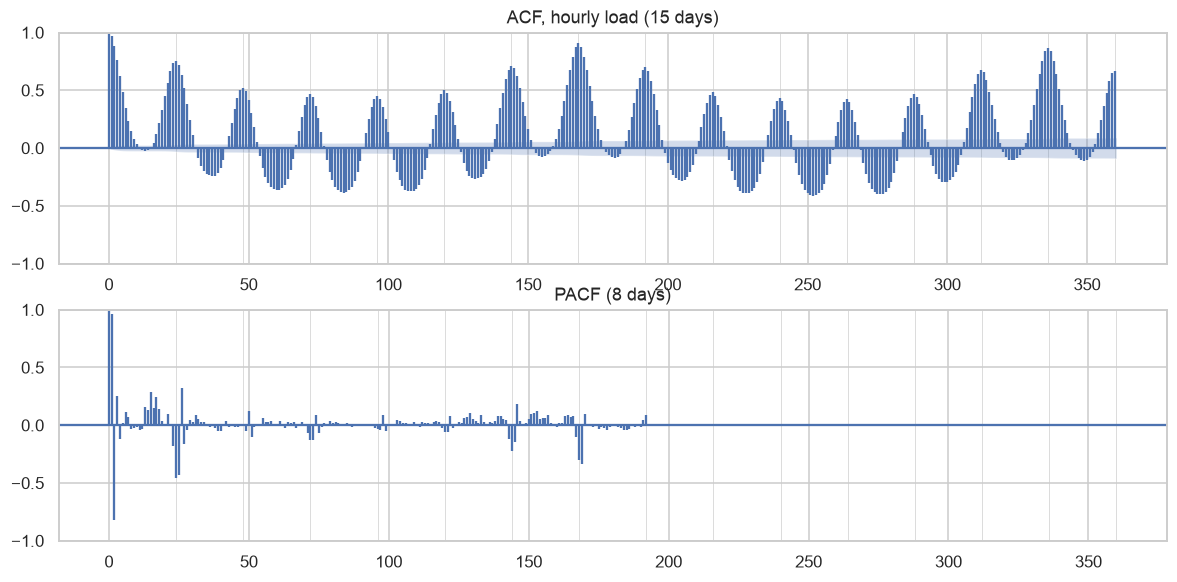

In [7]:
y = d[TARGET].loc[:"2020-02-29"]
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
plot_acf(y, lags=24 * 15, ax=axes[0], markersize=0, title="ACF, hourly load (15 days)")
plot_pacf(y, lags=24 * 8, ax=axes[1], markersize=0, method="ywm", title="PACF (8 days)")
for ax in axes:
    for k in range(24, 24 * 16, 24):
        ax.axvline(k, color="0.85", lw=0.6, zorder=0)
save(fig, "06_acf_pacf")
print({f"lag {k}h": round(y.autocorr(k), 3) for k in [1, 24, 48, 144, 168, 336]})

## 7. COVID-19: how big was the 2020 shock?

Largest weekly drop: -14.4% (week ending 2020-04-12)
Mean deviation Apr-May 2020: -9.0% | Jul-Sep: -4.6%


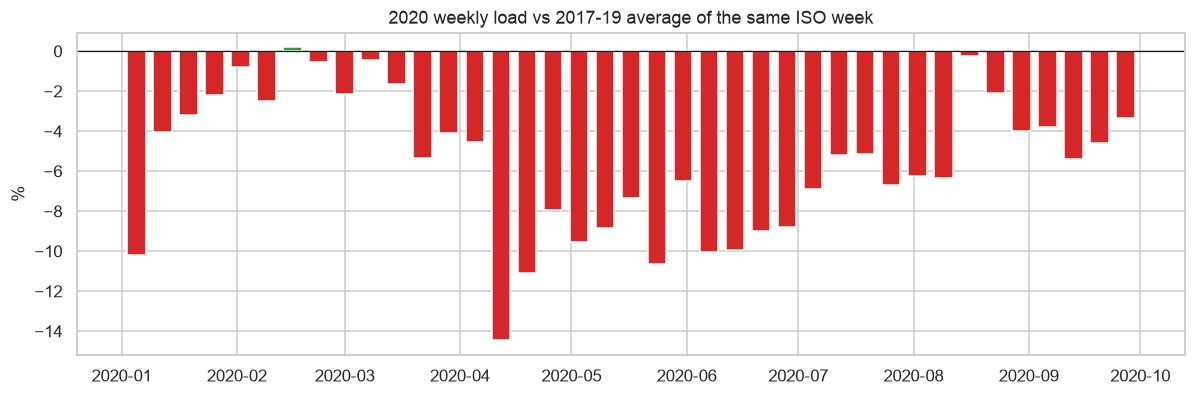

In [8]:
wk_load = d["load_gw"].resample("W-SUN").mean()
base = wk_load[wk_load.index.year.isin([2017, 2018, 2019])]
base = base.groupby(base.index.isocalendar().week.values).mean()
w20 = wk_load["2020-01-01":"2020-09-30"]
dev = (w20.values / base.reindex(w20.index.isocalendar().week.values).values - 1) * 100
dev = pd.Series(dev, index=w20.index)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(dev.index, dev, width=5, color=np.where(dev < 0, "tab:red", "tab:green"))
ax.axhline(0, color="k", lw=0.8)
ax.set(title="2020 weekly load vs 2017-19 average of the same ISO week", ylabel="%")
save(fig, "07_covid_2020")
print(f"Largest weekly drop: {dev.min():.1f}% (week ending {dev.idxmin().date()})")
print(
    f"Mean deviation Apr-May 2020: {dev['2020-04':'2020-05'].mean():.1f}% | Jul-Sep: {dev['2020-07':'2020-09'].mean():.1f}%"
)

## 8. The benchmark: TSOs' official day-ahead forecast

Note: the TSO forecast is issued around 10:00 on D-1, *earlier* than our 00:00 UTC cut-off,
so it has slightly less recent load information; but it uses real weather *forecasts*,
whereas our weather features are reanalysis actuals (a mild advantage for us).

,bias,MAE
utc_timestamp,,
2015,0.47,1.61
2016,1.56,2.03
2017,0.45,1.40
2018,0.47,1.58
2019,1.33,1.99
2020,-0.36,1.46


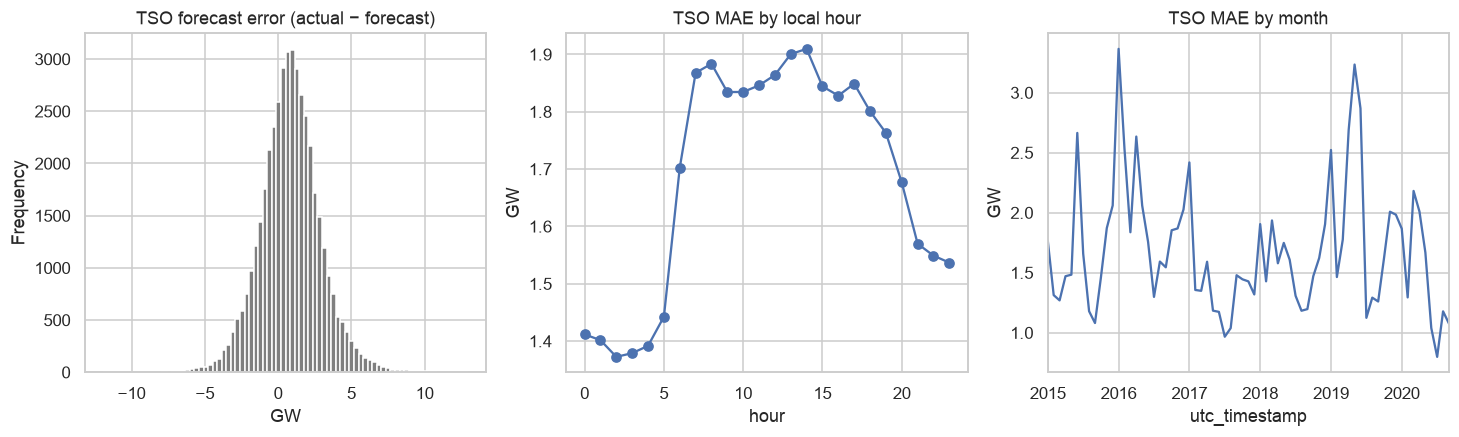

In [9]:
err = (d[TARGET] - d[TSO_FORECAST]) / 1000
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
err.loc[:"2019"].plot.hist(bins=80, ax=axes[0], color="tab:gray")
axes[0].set(title="TSO forecast error (actual − forecast)", xlabel="GW")
err.groupby(d.hour).agg(lambda s: s.abs().mean()).plot(ax=axes[1], marker="o")
axes[1].set(title="TSO MAE by local hour", xlabel="hour", ylabel="GW")
err.resample("ME").agg(lambda s: s.abs().mean()).plot(ax=axes[2])
axes[2].set(title="TSO MAE by month", ylabel="GW")
save(fig, "08_tso_forecast_error")
bias_by_year = (
    err.groupby(err.index.year).agg(bias="mean", MAE=lambda s: s.abs().mean()).round(2)
)
bias_by_year

## Takeaways → modeling decisions

Summarised in the project README / chat; the key numbers are printed in the cells above.